In [1]:
import logging

logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
)
from networkx import get_node_attributes, connected_components
from networkx.generators import path_graph

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# PAAm homopolymer

## Assemble MuPT repr

In [2]:
DOP: int = 10
lexicon = {
    "head": primitive_from_smiles(
        "[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]", label="_A"
    ),
    "mid": primitive_from_smiles(
        "[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]", label="_B"
    ),
    "tail": primitive_from_smiles(
        "[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]", label="_C"
    ),
}

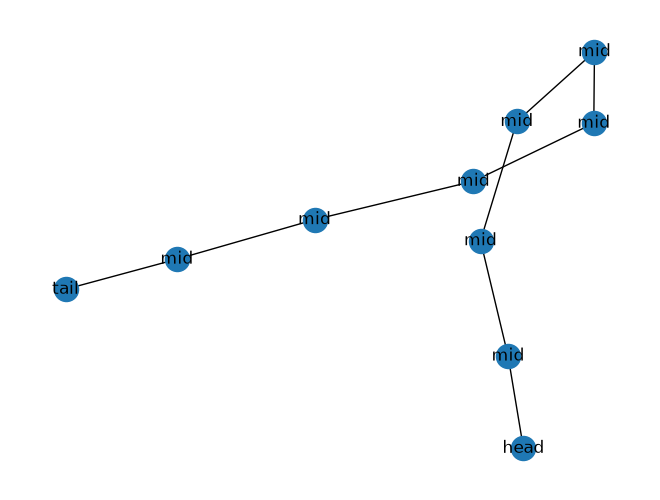

In [3]:
sequence = ["head"] + (DOP - 2) * ["mid"] + ["tail"]
sequence_graph = path_graph(len(sequence))
for i, label in enumerate(sequence):
    sequence_graph.nodes[i]["label"] = label

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, "label"),
)

### Select, connect, then inspect

In [4]:
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim, CompositePrimitive)
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
predicate: NodePredicate[Primitive] = is_subdominant

In [5]:
molprim = CompositePrimitive()
molprim.populate_from_topology_and_lexicon(
    sequence_graph, lexicon, label_attr="label"
)
xsec = molprim.cross_section(predicate)

print(f"{len(list(connected_components(xsec)))} molecules")

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


1 molecules


<Axes: >

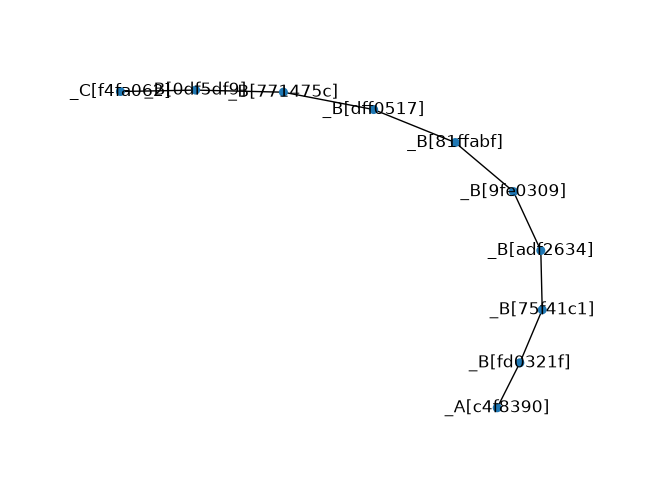

In [6]:
pos = spring_layout(xsec, dim=2)
molprim.visualize_cross_section(xsec, pos=pos, with_labels=True, node_size=30)

## Export to mbuild

In [7]:
compound = primitive_to_mbuild(molprim, predicate=predicate)
...  # insert downstream code here
print(compound)

<COMPOSITE 10 particles, 9 bonds, non-periodic, id: 5784315488>


In [8]:
compound.bonds()

EdgeView([(<_A pos=([0. 0. 0.]), 1 bonds, id: 5788582288>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5788582608>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5788582608>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5784415296>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5784415296>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5784415904>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5784415904>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5784189360>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5784189360>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5784253808>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5784253808>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5784253536>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5784253536>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5786720080>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5786720080>, <_B pos=([0. 0. 0.]), 2 bonds, id: 5786721872>), (<_B pos=([0. 0. 0.]), 2 bonds, id: 5786721872>, <_C pos=([0. 0. 0.]), 1 bonds, id: 5786997280>)])

In [9]:
import warnings

warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAMAM", identify_connections=False
)
molecules.compound.children[0].mass = 1

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


In [10]:
molecules.molecules

[<PAMAM 10 particles, 9 bonds, non-periodic, id: 5891723664>]

In [11]:
molecules

In [12]:
molecules.bond_types

{('_A', '_B'), ('_B', '_B'), ('_B', '_C')}

In [13]:
from flowermd.library import RandomWalk
import unyt as u

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    buffer=0.5,
    base_units=ref_values_dict,
    seed=456,
)
system.box

Box: Lx=2.320794, Ly=2.320794, Lz=2.320794, xy=0.000000, xz=0.000000, yz=0.000000, 

In [14]:
system.gmso_system.bond_types

<TopologyPotentialView(())>

In [15]:
from flowermd.library import Bead_Spring_DPD
import hoomd

nlist = hoomd.md.nlist.Cell(buffer=0.4, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

ParameterizationError: No parameters found for connection <Bond Bond, id: 6045606896> , group: bond_type, identifiers: <itertools.product object at 0x168637140> in the force field.

In [ ]:
from flowermd.library import PhantomWalk
import hoomd

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

In [ ]:
from cmeutils.visualize import FresnelGSD

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=0, view_axis=(1, 1, 1)
)
sim_visualizer.view()

In [ ]:
sim_visualizer.frame = -1
sim_visualizer.view()